In [3]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
train = pd.read_csv("/content/train.csv")

/tmp/ipykernel_965/479604980.py:1: DtypeWarning: Columns (22) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("/content/train.csv")


In [5]:
train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1.0,4.0,1.0,...,4.0,3.0,1.0,0.0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5.0,4.0,4.0,...,5.0,4.0,3.0,0.0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3.0,3.0,3.0,...,4.0,5.0,3.0,0.0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3.0,3.0,3.0,...,3.0,4.0,3.0,0.0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5.0,3.0,5.0,...,5.0,3.0,5.0,5.0,0.0,Female,disloyal Customer,Business travel,Eco,False


In [6]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

In [7]:
# 1. Prepare target and features first
x = train.drop(["id", "satisfaction"], axis=1)
y = train["satisfaction"]

# 2. Split into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=2)

# 3. Dynamically identify all numeric and categorical columns from our training features
num_cols = x_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = x_train.select_dtypes(exclude=[np.number]).columns.tolist()

# 4. Create robust pipelines to handle imputation and scaling without leaving NaNs
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(sparse_output=False, drop='first'))
])

tnf = ColumnTransformer(transformers=[
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
], remainder="drop")

In [8]:
# Fit and transform the train and test data safely using our complete imputation pipeline
x_train_transformed = tnf.fit_transform(x_train)
x_test_transformed = tnf.transform(x_test)

In [9]:
# Clean the target values by filling any unexpected NaNs and converting to numeric
y_train_clean = y_train.fillna(False).astype(bool).astype(np.float32)
y_test_clean = y_test.fillna(False).astype(bool).astype(np.float32)

/tmp/ipykernel_965/3324927055.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_train_clean = y_train.fillna(False).astype(bool).astype(np.float32)
/tmp/ipykernel_965/3324927055.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_test_clean = y_test.fillna(False).astype(bool).astype(np.float32)


In [10]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Define and build the Sequential neural network with correct input dimension matching
model = Sequential()
model.add(Dense(11, activation="relu", input_dim=x_train_transformed.shape[1]))
model.add(Dense(10, activation="relu"))
model.add(Dense(8, activation="relu"))
model.add(Dense(5, activation="relu"))
model.add(Dense(1, activation="sigmoid"))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 11)             │           253 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │            45 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 512 (2.00 KB)

 Trainable params: 512 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model = Sequential()

In [13]:
model.add(Dense(11, activation = "relu", input_dim = x_train.shape[1]))
model.add(Dense(10, activation = "relu"))
model.add(Dense(8, activation = "relu"))
model.add(Dense(5, activation = "relu"))
model.add(Dense(1, activation = "sigmoid"))


In [14]:
import numpy as np

# 2. Convert target labels to numeric float32, filling any NaN values if present
y_train = y_train.fillna(False).astype(bool).astype(np.float32)
y_test = y_test.fillna(False).astype(bool).astype(np.float32)

/tmp/ipykernel_965/273111871.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_train = y_train.fillna(False).astype(bool).astype(np.float32)
/tmp/ipykernel_965/273111871.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_test = y_test.fillna(False).astype(bool).astype(np.float32)


In [15]:
model.compile(loss = "binary_crossentropy", optimizer = "adam", metrics = ["accuracy"])

In [17]:
# Re-instantiate the model with correct input dimensions to match preprocessed shape (22 features)
model = Sequential()
model.add(Dense(11, activation="relu", input_dim=x_train_transformed.shape[1]))
model.add(Dense(10, activation="relu"))
model.add(Dense(8, activation="relu"))
model.add(Dense(5, activation="relu"))
model.add(Dense(1, activation="sigmoid"))

# Compile the model cleanly and train
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])

history = model.fit(
    x_train_transformed,
    y_train_clean,
    epochs=10,
    validation_data=(x_test_transformed, y_test_clean)
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
8743/8743 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - accuracy: 0.9027 - loss: 0.2780 - val_accuracy: 0.9155 - val_loss: 0.2487
Epoch 2/10
8743/8743 ━━━━━━━━━━━━━━━━━━━━ 26s 3ms/step - accuracy: 0.9154 - loss: 0.2505 - val_accuracy: 0.9182 - val_loss: 0.2440
Epoch 3/10
8743/8743 ━━━━━━━━━━━━━━━━━━━━ 34s 4ms/step - accuracy: 0.9175 - loss: 0.2464 - val_accuracy: 0.9203 - val_loss: 0.2422
Epoch 4/10
8743/8743 ━━━━━━━━━━━━━━━━━━━━ 26s 3ms/step - accuracy: 0.9188 - loss: 0.2444 - val_accuracy: 0.9207 - val_loss: 0.2399
Epoch 5/10
8743/8743 ━━━━━━━━━━━━━━━━━━━━ 34s 4ms/step - accuracy: 0.9194 - loss: 0.2429 - val_accuracy: 0.9212 - val_loss: 0.2390
Epoch 6/10
8743/8743 ━━━━━━━━━━━━━━━━━━━━ 32s 4ms/step - accuracy: 0.9201 - loss: 0.2419 - val_accuracy: 0.9216 - val_loss: 0.2372
Epoch 7/10
8743/8743 ━━━━━━━━━━━━━━━━━━━━ 26s 3ms/step - accuracy: 0.9202 - loss: 0.2410 - val_accuracy: 0.9214 - val_loss: 0.2389
Epoch 8/10
8743/8743 ━━━━━━━━━━━━━━━━━━━━ 26s 3ms/step - accuracy: 0.9207 - loss: 0

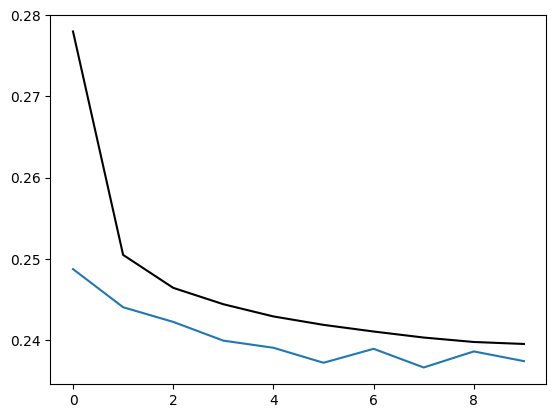

In [18]:
plt.plot(history.history["loss"],color = "black")
plt.plot(history.history["val_loss"])

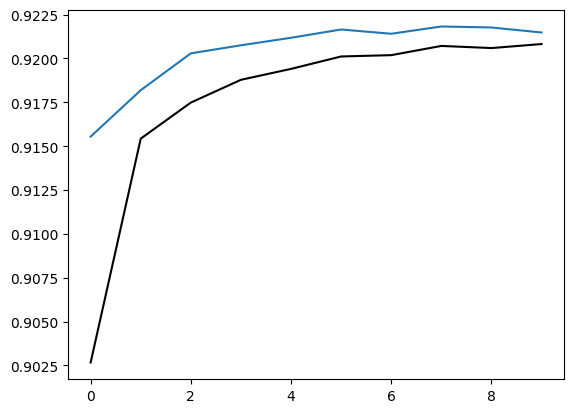

In [22]:
plt.plot(history.history["accuracy"], color = "black")
plt.plot(history.history["val_accuracy"])
#plt.ylim(0.78,0.86)

In [23]:
from tensorflow.keras.layers import Input, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

# 1. Build an optimized deeper neural network with Batch Normalization and Dropout
opt_model = Sequential([
    Input(shape=(x_train_transformed.shape[1],)),

    Dense(32, activation="relu"),
    BatchNormalization(),
    Dropout(0.2),

    Dense(16, activation="relu"),
    BatchNormalization(),
    Dropout(0.2),

    Dense(8, activation="relu"),
    BatchNormalization(),

    Dense(1, activation="sigmoid")
])

# 2. Compile with Adam optimizer
opt_model.compile(
    loss="binary_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    metrics=["accuracy"]
)

# 3. Setup Early Stopping to restore the best weights when validation loss bottoms out
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# 4. Fit the improved model for up to 30 epochs
opt_history = opt_model.fit(
    x_train_transformed,
    y_train_clean,
    epochs=30,
    batch_size=64,
    validation_data=(x_test_transformed, y_test_clean),
    callbacks=[early_stopping]
)

Epoch 1/30
4372/4372 ━━━━━━━━━━━━━━━━━━━━ 25s 5ms/step - accuracy: 0.8871 - loss: 0.3124 - val_accuracy: 0.9154 - val_loss: 0.2502
Epoch 2/30
4372/4372 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.9064 - loss: 0.2718 - val_accuracy: 0.9197 - val_loss: 0.2437
Epoch 3/30
4372/4372 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.9103 - loss: 0.2645 - val_accuracy: 0.9205 - val_loss: 0.2399
Epoch 4/30
4372/4372 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.9115 - loss: 0.2614 - val_accuracy: 0.9221 - val_loss: 0.2387
Epoch 5/30
4372/4372 ━━━━━━━━━━━━━━━━━━━━ 15s 3ms/step - accuracy: 0.9127 - loss: 0.2598 - val_accuracy: 0.9214 - val_loss: 0.2398
Epoch 6/30
4372/4372 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.9144 - loss: 0.2573 - val_accuracy: 0.9227 - val_loss: 0.2371
Epoch 7/30
4372/4372 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.9148 - loss: 0.2564 - val_accuracy: 0.9220 - val_loss: 0.2382
Epoch 8/30
4372/4372 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.9147 - loss: 0

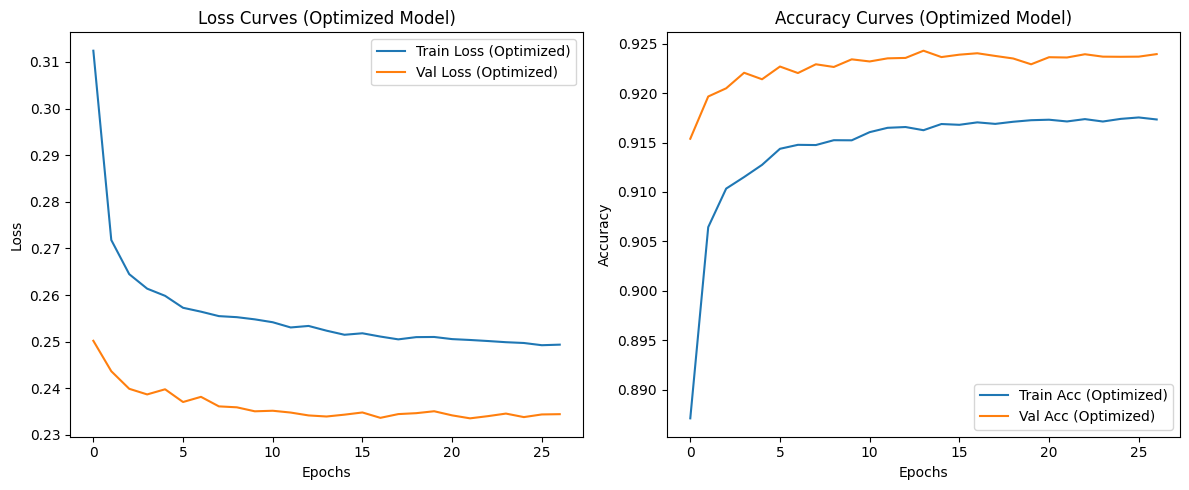

In [24]:
# Compare the original and improved training curves
plt.figure(figsize=(12, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(opt_history.history["loss"], label="Train Loss (Optimized)")
plt.plot(opt_history.history["val_loss"], label="Val Loss (Optimized)")
plt.title("Loss Curves (Optimized Model)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(opt_history.history["accuracy"], label="Train Acc (Optimized)")
plt.plot(opt_history.history["val_accuracy"], label="Val Acc (Optimized)")
plt.title("Accuracy Curves (Optimized Model)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [25]:
# Evaluate the optimized model on the transformed test set
loss, accuracy = opt_model.evaluate(x_test_transformed, y_test_clean, verbose=1)
print(f"\nFinal Test Accuracy: {accuracy * 100:.2f}%")
print(f"Final Test Loss: {loss:.4f}")

2186/2186 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9236 - loss: 0.2336

Final Test Accuracy: 92.36%
Final Test Loss: 0.2336


### LightGBM Model Overview (Accuracy: 0.925)

While the deep learning model achieved great results (~92.4%), **LightGBM** (Light Gradient Boosting Machine) pushed performance to **0.925 accuracy** due to several structural advantages:

* **Tabular Optimization**: Being a gradient-boosted decision tree framework, LightGBM is inherently suited for tabular datasets and handles non-linear relationships much more robustly than basic neural networks.
* **Leaf-wise Tree Growth**: Instead of level-wise splitting, LightGBM splits leaf-wise on the node that yields the largest loss reduction, allowing it to capture finer interactions between features.
* **Speed and Efficiency**: It trains much faster and requires significantly fewer computational resources compared to multi-layer perceptrons.